In [37]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [38]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [39]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


In [40]:
# ============================================================
# CELL 1: COMMON SETUP
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import (
    DataLoader,
    WeightedRandomSampler,
    random_split
)

from torchvision import datasets, transforms, models

from tqdm import tqdm

import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

from sklearn.svm import SVC
from xgboost import XGBClassifier


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# DATASET PATHS
# ============================================================

train_dir = "/kaggle/working/PCOSGen-train/train"
test_dir = "/kaggle/working/PCOSGen-train/test"


# ============================================================
# IMAGE TRANSFORMS
# Same as your existing baseline
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# DATASETS
# ============================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

num_classes = len(train_dataset.classes)

print("Classes:", train_dataset.classes)
print("Number of classes:", num_classes)
print("Total training images:", len(train_dataset))
print("Total test images:", len(test_dataset))


# ============================================================
# 85% TRAIN / 15% VALIDATION SPLIT
# Test remains completely separate
# ============================================================

val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)

print("\nTrain images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Test images:", len(test_dataset))


# ============================================================
# WEIGHTED RANDOM SAMPLER
# Same as your baseline
# ============================================================

train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(train_targets)

class_weights = 1.0 / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


# ============================================================
# DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("\nDataLoaders ready.")

Device: cuda
Classes: ['Appears abnormal', 'Appears normal']
Number of classes: 2
Total training images: 3200
Total test images: 1468

Train images: 2720
Validation images: 480
Test images: 1468

DataLoaders ready.


# ResNet18

In [41]:
# =========================
# 2A — RESNET18 BASELINE
# =========================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import models

# -------------------------
# Model
# -------------------------
resnet = models.resnet18(pretrained=True)

resnet.fc = nn.Linear(
    resnet.fc.in_features,
    num_classes
)

resnet = resnet.to(device)

# -------------------------
# Dice Loss
# -------------------------
class DiceLoss(nn.Module):
    def __init__(self):
        super(DiceLoss, self).__init__()

    def forward(self, inputs, targets):
        num_classes = inputs.shape[1]

        probs = F.softmax(inputs, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=num_classes
        ).float()

        dims = (0, 2, 3) if probs.dim() == 4 else (0,)

        intersection = torch.sum(
            probs * targets_one_hot,
            dim=dims
        )

        cardinality = torch.sum(
            probs + targets_one_hot,
            dim=dims
        )

        dice = (2.0 * intersection + 1e-7) / (
            cardinality + 1e-7
        )

        return 1 - dice.mean()


# -------------------------
# Combined Loss
# -------------------------
class CombinedLoss(nn.Module):
    def __init__(self, ce_weight=0.5, dice_weight=0.5):
        super(CombinedLoss, self).__init__()

        self.ce = nn.CrossEntropyLoss()
        self.dice = DiceLoss()

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, outputs, targets):
        ce_loss = self.ce(outputs, targets)
        dice_loss = self.dice(outputs, targets)

        return (
            self.ce_weight * ce_loss +
            self.dice_weight * dice_loss
        )


criterion = CombinedLoss(
    ce_weight=0.5,
    dice_weight=0.5
)

optimizer = optim.Adam(
    resnet.parameters(),
    lr=0.001
)

# -------------------------
# Validation function
# -------------------------
def evaluate_resnet(model, loader):
    model.eval()

    correct = 0
    total = 0

    total_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = correct / total
    loss = total_loss / total

    return loss, accuracy


# -------------------------
# Training
# -------------------------
best_accuracy = 0.0
best_model_path = "/kaggle/working/Resnet18_pcos.pkl"

patience = 8
epochs_no_improve = 0
max_epochs = 50

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(max_epochs):

    resnet.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_accuracy = correct / total

    val_loss, val_accuracy = evaluate_resnet(
        resnet,
        val_loader
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # -------------------------
    # Early stopping
    # -------------------------
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        torch.save(
            resnet.state_dict(),
            best_model_path
        )

        epochs_no_improve = 0

    else:

        epochs_no_improve += 1

        if epochs_no_improve >= patience:
            break


# -------------------------
# Load best model
# -------------------------
best_resnet_model = models.resnet18(
    pretrained=False
)

best_resnet_model.fc = nn.Linear(
    best_resnet_model.fc.in_features,
    num_classes
)

best_resnet_model = best_resnet_model.to(device)

best_resnet_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

best_resnet_model.eval()


# -------------------------
# Feature Extraction
# -------------------------
def extract_resnet_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            x = model.conv1(images)
            x = model.bn1(x)
            x = model.relu(x)
            x = model.maxpool(x)

            x = model.layer1(x)
            x = model.layer2(x)
            x = model.layer3(x)
            x = model.layer4(x)

            x = model.avgpool(x)

            x = torch.flatten(x, 1)

            features.append(
                x.cpu()
            )

            labels_list.append(
                labels.cpu()
            )

    features = torch.cat(features).numpy()
    labels_list = torch.cat(labels_list).numpy()

    return features, labels_list


resnet_train_features, resnet_train_labels = extract_resnet_features(
    best_resnet_model,
    train_loader
)

resnet_val_features, resnet_val_labels = extract_resnet_features(
    best_resnet_model,
    val_loader
)

resnet_test_features, resnet_test_labels = extract_resnet_features(
    best_resnet_model,
    test_loader
)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


# XGboost

ResNet18 + XGBoost
XGBoost Validation Accuracy: 0.6917

Test Metrics:
Test Accuracy:  0.8869
Test Precision: 0.8860
Test Recall:    0.8869
Test F1-score:  0.8864

Classification Report:

              precision    recall  f1-score   support

    Non-PCOS       0.92      0.93      0.92      1052
        PCOS       0.81      0.79      0.80       416

    accuracy                           0.89      1468
   macro avg       0.86      0.86      0.86      1468
weighted avg       0.89      0.89      0.89      1468



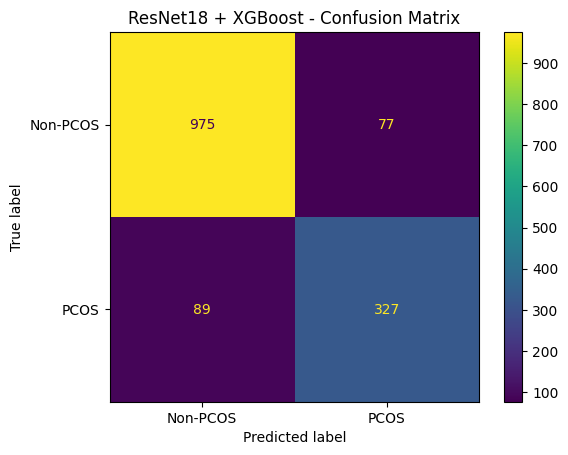

In [43]:
# ============================================================
# 2B — ResNet18 + XGBoost
# ============================================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Create XGBoost Classifier
# ------------------------------------------------------------

resnet_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric="logloss"
)


# ------------------------------------------------------------
# 2. Train XGBoost on ResNet18 TRAIN features
# ------------------------------------------------------------

resnet_xgb.fit(
    resnet_train_features,
    resnet_train_labels
)


# ------------------------------------------------------------
# 3. Validation Prediction
# ------------------------------------------------------------

resnet_xgb_val_pred = resnet_xgb.predict(
    resnet_val_features
)

resnet_xgb_val_accuracy = accuracy_score(
    resnet_val_labels,
    resnet_xgb_val_pred
)

print("===================================")
print("ResNet18 + XGBoost")
print("===================================")
print(f"XGBoost Validation Accuracy: {resnet_xgb_val_accuracy:.4f}")


# ------------------------------------------------------------
# 4. Test Prediction
# ------------------------------------------------------------

resnet_xgb_test_pred = resnet_xgb.predict(
    resnet_test_features
)


# ------------------------------------------------------------
# 5. Test Metrics
# ------------------------------------------------------------

resnet_xgb_test_accuracy = accuracy_score(
    resnet_test_labels,
    resnet_xgb_test_pred
)

resnet_xgb_test_precision = precision_score(
    resnet_test_labels,
    resnet_xgb_test_pred,
    average="weighted",
    zero_division=0
)

resnet_xgb_test_recall = recall_score(
    resnet_test_labels,
    resnet_xgb_test_pred,
    average="weighted",
    zero_division=0
)

resnet_xgb_test_f1 = f1_score(
    resnet_test_labels,
    resnet_xgb_test_pred,
    average="weighted",
    zero_division=0
)


# ------------------------------------------------------------
# 6. Print Test Metrics
# ------------------------------------------------------------

print("\nTest Metrics:")
print(f"Test Accuracy:  {resnet_xgb_test_accuracy:.4f}")
print(f"Test Precision: {resnet_xgb_test_precision:.4f}")
print(f"Test Recall:    {resnet_xgb_test_recall:.4f}")
print(f"Test F1-score:  {resnet_xgb_test_f1:.4f}")


# ------------------------------------------------------------
# 7. Classification Report
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(
    classification_report(
        resnet_test_labels,
        resnet_xgb_test_pred,
        target_names=["Non-PCOS", "PCOS"],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 8. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    resnet_test_labels,
    resnet_xgb_test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-PCOS", "PCOS"]
)

disp.plot()

plt.title("ResNet18 + XGBoost - Confusion Matrix")
plt.show()

# SVM

ResNet18 + SVM
SVM Validation Accuracy: 0.5792
SVM Test Accuracy: 0.8672
SVM Test Precision: 0.8867
SVM Test Recall: 0.8672
SVM Test F1-score: 0.8714

Classification Report:

              precision    recall  f1-score   support

    Non-PCOS       0.96      0.85      0.90      1052
        PCOS       0.71      0.90      0.79       416

    accuracy                           0.87      1468
   macro avg       0.83      0.88      0.85      1468
weighted avg       0.89      0.87      0.87      1468



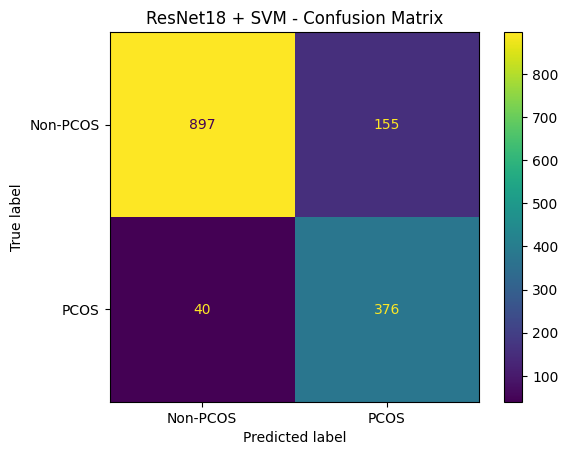

In [45]:
# ============================================================
# 2C — ResNet18 + SVM
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Create SVM Classifier
# ------------------------------------------------------------

resnet_svm = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)


# ------------------------------------------------------------
# 2. Train SVM on ResNet18 TRAIN features
# ------------------------------------------------------------

resnet_svm.fit(
    resnet_train_features,
    resnet_train_labels
)


# ------------------------------------------------------------
# 3. Validation Prediction
# ------------------------------------------------------------

resnet_svm_val_pred = resnet_svm.predict(
    resnet_val_features
)

resnet_svm_val_accuracy = accuracy_score(
    resnet_val_labels,
    resnet_svm_val_pred
)

print("==============================")
print("ResNet18 + SVM")
print("==============================")
print(f"SVM Validation Accuracy: {resnet_svm_val_accuracy:.4f}")


# ------------------------------------------------------------
# 4. Test Prediction
# ------------------------------------------------------------

resnet_svm_test_pred = resnet_svm.predict(
    resnet_test_features
)


# ------------------------------------------------------------
# 5. Test Metrics
# ------------------------------------------------------------

resnet_svm_test_accuracy = accuracy_score(
    resnet_test_labels,
    resnet_svm_test_pred
)

resnet_svm_test_precision = precision_score(
    resnet_test_labels,
    resnet_svm_test_pred,
    average="weighted",
    zero_division=0
)

resnet_svm_test_recall = recall_score(
    resnet_test_labels,
    resnet_svm_test_pred,
    average="weighted",
    zero_division=0
)

resnet_svm_test_f1 = f1_score(
    resnet_test_labels,
    resnet_svm_test_pred,
    average="weighted",
    zero_division=0
)


# ------------------------------------------------------------
# 6. Print Test Metrics
# ------------------------------------------------------------

print(f"SVM Test Accuracy: {resnet_svm_test_accuracy:.4f}")
print(f"SVM Test Precision: {resnet_svm_test_precision:.4f}")
print(f"SVM Test Recall: {resnet_svm_test_recall:.4f}")
print(f"SVM Test F1-score: {resnet_svm_test_f1:.4f}")


# ------------------------------------------------------------
# 7. Classification Report
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(
    classification_report(
        resnet_test_labels,
        resnet_svm_test_pred,
        target_names=["Non-PCOS", "PCOS"],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 8. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    resnet_test_labels,
    resnet_svm_test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-PCOS", "PCOS"]
)

disp.plot()

plt.title("ResNet18 + SVM - Confusion Matrix")
plt.show()

# MobileNet V2

In [46]:
# =========================
# 3A — MOBILENETV2 BASELINE
# =========================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import models

# -------------------------
# Model
# -------------------------
mobilenet = models.mobilenet_v2(pretrained=True)

mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

mobilenet = mobilenet.to(device)


# -------------------------
# Dice Loss
# -------------------------
class DiceLossMobileNet(nn.Module):
    def __init__(self):
        super(DiceLossMobileNet, self).__init__()

    def forward(self, inputs, targets):

        num_classes = inputs.shape[1]

        probs = F.softmax(inputs, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=num_classes
        ).float()

        intersection = torch.sum(
            probs * targets_one_hot,
            dim=0
        )

        cardinality = torch.sum(
            probs + targets_one_hot,
            dim=0
        )

        dice = (
            2.0 * intersection + 1e-7
        ) / (
            cardinality + 1e-7
        )

        return 1 - dice.mean()


# -------------------------
# Combined Loss
# -------------------------
class CombinedLossMobileNet(nn.Module):
    def __init__(self, ce_weight=0.5, dice_weight=0.5):
        super(CombinedLossMobileNet, self).__init__()

        self.ce = nn.CrossEntropyLoss()
        self.dice = DiceLossMobileNet()

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, outputs, targets):

        ce_loss = self.ce(outputs, targets)
        dice_loss = self.dice(outputs, targets)

        return (
            self.ce_weight * ce_loss +
            self.dice_weight * dice_loss
        )


criterion_mobilenet = CombinedLossMobileNet(
    ce_weight=0.5,
    dice_weight=0.5
)

optimizer_mobilenet = optim.Adam(
    mobilenet.parameters(),
    lr=0.001
)


# -------------------------
# Validation
# -------------------------
def evaluate_mobilenet(model, loader):

    model.eval()

    correct = 0
    total = 0
    total_loss = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion_mobilenet(
                outputs,
                labels
            )

            total_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total
    loss = total_loss / total

    return loss, accuracy


# -------------------------
# Training
# -------------------------
best_accuracy = 0.0

best_model_path = (
    "/kaggle/working/Mobilenet_1410=.pkl"
)

patience = 8
epochs_no_improve = 0
max_epochs = 50

train_losses_mobilenet = []
val_losses_mobilenet = []

train_accuracies_mobilenet = []
val_accuracies_mobilenet = []


for epoch in range(max_epochs):

    mobilenet.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_mobilenet.zero_grad()

        outputs = mobilenet(images)

        loss = criterion_mobilenet(
            outputs,
            labels
        )

        loss.backward()

        optimizer_mobilenet.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    train_loss = running_loss / total
    train_accuracy = correct / total

    val_loss, val_accuracy = evaluate_mobilenet(
        mobilenet,
        val_loader
    )

    train_losses_mobilenet.append(
        train_loss
    )

    val_losses_mobilenet.append(
        val_loss
    )

    train_accuracies_mobilenet.append(
        train_accuracy
    )

    val_accuracies_mobilenet.append(
        val_accuracy
    )

    # -------------------------
    # Early Stopping
    # -------------------------
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        torch.save(
            mobilenet.state_dict(),
            best_model_path
        )

        epochs_no_improve = 0

    else:

        epochs_no_improve += 1

        if epochs_no_improve >= patience:
            break


# -------------------------
# Load Best Model
# -------------------------
best_mobilenet_model = models.mobilenet_v2(
    pretrained=False
)

best_mobilenet_model.classifier[1] = nn.Linear(
    best_mobilenet_model.classifier[1].in_features,
    num_classes
)

best_mobilenet_model = best_mobilenet_model.to(device)

best_mobilenet_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

best_mobilenet_model.eval()


# -------------------------
# Feature Extraction
# -------------------------
def extract_mobilenet_features(
    model,
    loader
):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            x = model.features(images)

            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            x = torch.flatten(
                x,
                1
            )

            features.append(
                x.cpu()
            )

            labels_list.append(
                labels.cpu()
            )

    features = torch.cat(
        features
    ).numpy()

    labels_list = torch.cat(
        labels_list
    ).numpy()

    return features, labels_list


mobilenet_train_features, mobilenet_train_labels = (
    extract_mobilenet_features(
        best_mobilenet_model,
        train_loader
    )
)

mobilenet_val_features, mobilenet_val_labels = (
    extract_mobilenet_features(
        best_mobilenet_model,
        val_loader
    )
)

mobilenet_test_features, mobilenet_test_labels = (
    extract_mobilenet_features(
        best_mobilenet_model,
        test_loader
    )
)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


# XGboost

MobileNetV2 + XGBoost
XGBoost Validation Accuracy: 0.6604
XGBoost Test Accuracy: 0.8672
XGBoost Test Precision: 0.8665
XGBoost Test Recall: 0.8672
XGBoost Test F1-score: 0.8668

Classification Report:

              precision    recall  f1-score   support

    Non-PCOS       0.90      0.91      0.91      1052
        PCOS       0.77      0.76      0.76       416

    accuracy                           0.87      1468
   macro avg       0.84      0.83      0.84      1468
weighted avg       0.87      0.87      0.87      1468



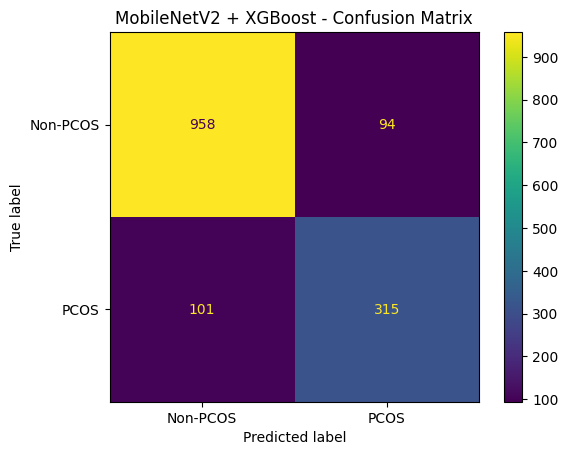

In [47]:
# ============================================================
# 3B — MobileNetV2 + XGBoost
# ============================================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# XGBoost
mobilenet_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric="logloss"
)

# Train
mobilenet_xgb.fit(
    mobilenet_train_features,
    mobilenet_train_labels
)

# Validation
mobilenet_xgb_val_pred = mobilenet_xgb.predict(
    mobilenet_val_features
)

mobilenet_xgb_val_accuracy = accuracy_score(
    mobilenet_val_labels,
    mobilenet_xgb_val_pred
)

print("==============================")
print("MobileNetV2 + XGBoost")
print("==============================")
print(f"XGBoost Validation Accuracy: {mobilenet_xgb_val_accuracy:.4f}")

# Test
mobilenet_xgb_test_pred = mobilenet_xgb.predict(
    mobilenet_test_features
)

# Metrics
mobilenet_xgb_test_accuracy = accuracy_score(
    mobilenet_test_labels,
    mobilenet_xgb_test_pred
)

mobilenet_xgb_test_precision = precision_score(
    mobilenet_test_labels,
    mobilenet_xgb_test_pred,
    average="weighted",
    zero_division=0
)

mobilenet_xgb_test_recall = recall_score(
    mobilenet_test_labels,
    mobilenet_xgb_test_pred,
    average="weighted",
    zero_division=0
)

mobilenet_xgb_test_f1 = f1_score(
    mobilenet_test_labels,
    mobilenet_xgb_test_pred,
    average="weighted",
    zero_division=0
)

print(f"XGBoost Test Accuracy: {mobilenet_xgb_test_accuracy:.4f}")
print(f"XGBoost Test Precision: {mobilenet_xgb_test_precision:.4f}")
print(f"XGBoost Test Recall: {mobilenet_xgb_test_recall:.4f}")
print(f"XGBoost Test F1-score: {mobilenet_xgb_test_f1:.4f}")

# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        mobilenet_test_labels,
        mobilenet_xgb_test_pred,
        labels=[0, 1],
        target_names=["Non-PCOS", "PCOS"],
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    mobilenet_test_labels,
    mobilenet_xgb_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-PCOS", "PCOS"]
)

disp.plot()
plt.title("MobileNetV2 + XGBoost - Confusion Matrix")
plt.show()

# SVM

MobileNetV2 + SVM
SVM Validation Accuracy: 0.6042
SVM Test Accuracy: 0.8896
SVM Test Precision: 0.8940
SVM Test Recall: 0.8896
SVM Test F1-score: 0.8911

Classification Report:

              precision    recall  f1-score   support

    Non-PCOS       0.94      0.90      0.92      1052
        PCOS       0.78      0.85      0.81       416

    accuracy                           0.89      1468
   macro avg       0.86      0.88      0.87      1468
weighted avg       0.89      0.89      0.89      1468



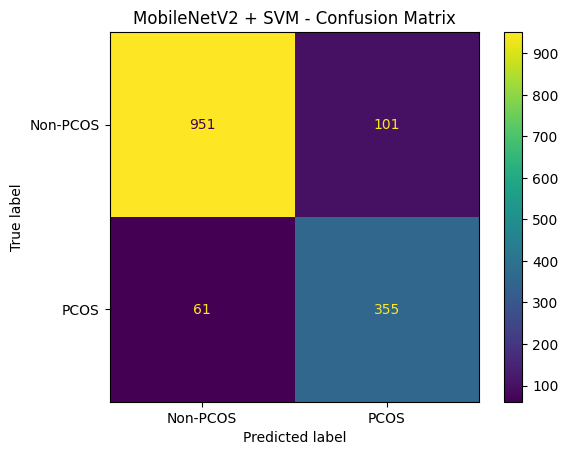

In [48]:
# ============================================================
# 3C — MobileNetV2 + SVM
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# SVM
mobilenet_svm = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)

# Train
mobilenet_svm.fit(
    mobilenet_train_features,
    mobilenet_train_labels
)

# Validation
mobilenet_svm_val_pred = mobilenet_svm.predict(
    mobilenet_val_features
)

mobilenet_svm_val_accuracy = accuracy_score(
    mobilenet_val_labels,
    mobilenet_svm_val_pred
)

print("==============================")
print("MobileNetV2 + SVM")
print("==============================")
print(f"SVM Validation Accuracy: {mobilenet_svm_val_accuracy:.4f}")

# Test
mobilenet_svm_test_pred = mobilenet_svm.predict(
    mobilenet_test_features
)

# Metrics
mobilenet_svm_test_accuracy = accuracy_score(
    mobilenet_test_labels,
    mobilenet_svm_test_pred
)

mobilenet_svm_test_precision = precision_score(
    mobilenet_test_labels,
    mobilenet_svm_test_pred,
    average="weighted",
    zero_division=0
)

mobilenet_svm_test_recall = recall_score(
    mobilenet_test_labels,
    mobilenet_svm_test_pred,
    average="weighted",
    zero_division=0
)

mobilenet_svm_test_f1 = f1_score(
    mobilenet_test_labels,
    mobilenet_svm_test_pred,
    average="weighted",
    zero_division=0
)

print(f"SVM Test Accuracy: {mobilenet_svm_test_accuracy:.4f}")
print(f"SVM Test Precision: {mobilenet_svm_test_precision:.4f}")
print(f"SVM Test Recall: {mobilenet_svm_test_recall:.4f}")
print(f"SVM Test F1-score: {mobilenet_svm_test_f1:.4f}")

# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        mobilenet_test_labels,
        mobilenet_svm_test_pred,
        labels=[0, 1],
        target_names=["Non-PCOS", "PCOS"],
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    mobilenet_test_labels,
    mobilenet_svm_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-PCOS", "PCOS"]
)

disp.plot()
plt.title("MobileNetV2 + SVM - Confusion Matrix")
plt.show()

# AlexNet

In [55]:
# ============================================================
# 4A — ALEXNET BASELINE
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim


# ============================================================
# AlexNet Architecture
# ============================================================

class AlexNet(nn.Module):

    def __init__(self, num_classes):

        super(AlexNet, self).__init__()

        self.conv1 = nn.Conv2d(
            3, 96,
            kernel_size=11,
            stride=4
        )

        self.conv2 = nn.Conv2d(
            96, 256,
            kernel_size=5,
            padding=2
        )

        self.conv3 = nn.Conv2d(
            256, 384,
            kernel_size=3,
            padding=1
        )

        self.conv4 = nn.Conv2d(
            384, 384,
            kernel_size=3,
            padding=1
        )

        self.conv5 = nn.Conv2d(
            384, 256,
            kernel_size=3,
            padding=1
        )

        self.maxpool = nn.MaxPool2d(
            kernel_size=3,
            stride=2
        )

        self.dropout = nn.Dropout(0.5)

        # Determine flattened feature size
        self._to_linear = None

        self.convs(
            torch.randn(
                1, 3, 224, 224
            )
        )

        self.fc1 = nn.Linear(
            self._to_linear,
            4096
        )

        self.fc2 = nn.Linear(
            4096,
            4096
        )

        self.fc3 = nn.Linear(
            4096,
            num_classes
        )

    def convs(self, x):

        x = F.relu(
            self.conv1(x)
        )

        x = self.maxpool(x)

        x = F.relu(
            self.conv2(x)
        )

        x = self.maxpool(x)

        x = F.relu(
            self.conv3(x)
        )

        x = F.relu(
            self.conv4(x)
        )

        x = F.relu(
            self.conv5(x)
        )

        x = self.maxpool(x)

        if self._to_linear is None:

            self._to_linear = (
                x.view(
                    x.size(0),
                    -1
                ).shape[1]
            )

        return x

    def forward(self, x):

        x = self.convs(x)

        x = x.view(
            x.size(0),
            -1
        )

        x = F.relu(
            self.fc1(x)
        )

        x = self.dropout(x)

        x = F.relu(
            self.fc2(x)
        )

        x = self.dropout(x)

        x = self.fc3(x)

        return x


# ============================================================
# Create AlexNet
# ============================================================

alexnet = AlexNet(
    num_classes
).to(device)


# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):

        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth

    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            +
            targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2.0 * intersection
            + self.smooth
        ) / (
            union
            + self.smooth
        )

        return 1.0 - dice_score.mean()


# ============================================================
# Combined Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(
        self,
        outputs,
        targets
    ):

        ce_loss = self.ce_loss(
            outputs,
            targets
        )

        dice_loss = self.dice_loss(
            outputs,
            targets
        )

        total_loss = (
            self.ce_weight * ce_loss
            +
            self.dice_weight * dice_loss
        )

        return (
            total_loss,
            ce_loss,
            dice_loss
        )


criterion = CombinedLoss(
    num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# Optimizer
# ============================================================

optimizer = optim.Adam(
    alexnet.parameters(),
    lr=0.001
)


# ============================================================
# Validation
# ============================================================

def evaluate_alexnet(
    model,
    loader
):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n_batches = len(loader)

    avg_loss = running_loss / n_batches
    avg_ce = running_ce / n_batches
    avg_dice = running_dice / n_batches

    return (
        accuracy,
        avg_loss,
        avg_ce,
        avg_dice
    )


# ============================================================
# Early Stopping
# ============================================================

best_accuracy = 0.0

best_model_path = (
    "/kaggle/working/AlexNet_best.pkl"
)

patience = 8
epochs_no_improve = 0
max_epochs = 50


# ============================================================
# Training History
# ============================================================

train_losses = []
train_accs = []

val_losses = []
val_accs = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# Training
# ============================================================

for epoch in range(max_epochs):

    alexnet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = alexnet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()

    # Training metrics
    train_accuracy = (
        correct_train /
        total_train
    )

    n_batches = len(train_loader)

    train_loss = (
        running_loss /
        n_batches
    )

    train_ce = (
        running_ce /
        n_batches
    )

    train_dice = (
        running_dice /
        n_batches
    )

    # Validation
    (
        val_accuracy,
        val_loss,
        val_ce,
        val_dice
    ) = evaluate_alexnet(
        alexnet,
        val_loader
    )

    # Save history
    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    train_ce_losses.append(train_ce)
    train_dice_losses.append(train_dice)

    val_ce_losses.append(val_ce)
    val_dice_losses.append(val_dice)

    # Early stopping
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        torch.save(
            alexnet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        if epochs_no_improve >= patience:
            break


# ============================================================
# Load Best Model
# ============================================================

best_alexnet_model = AlexNet(
    num_classes
).to(device)

best_alexnet_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

best_alexnet_model.eval()


# ============================================================
# Feature Extraction
# ============================================================

def extract_alexnet_features(
    model,
    loader
):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # ONLY CNN FEATURES
            x = model.convs(
                images
            )

            x = torch.flatten(
                x,
                1
            )

            features.append(
                x.cpu()
            )

            labels_list.append(
                labels.cpu()
            )

    features = torch.cat(
        features,
        dim=0
    ).numpy()

    labels_list = torch.cat(
        labels_list,
        dim=0
    ).numpy()

    return (
        features,
        labels_list
    )


# ============================================================
# TRAIN FEATURES
# ============================================================

alexnet_train_features, alexnet_train_labels = (
    extract_alexnet_features(
        best_alexnet_model,
        train_loader
    )
)


# ============================================================
# VALIDATION FEATURES
# ============================================================

alexnet_val_features, alexnet_val_labels = (
    extract_alexnet_features(
        best_alexnet_model,
        val_loader
    )
)


# ============================================================
# TEST FEATURES
# ============================================================

alexnet_test_features, alexnet_test_labels = (
    extract_alexnet_features(
        best_alexnet_model,
        test_loader
    )
)

# XGboost

AlexNet + XGBoost
XGBoost Validation Accuracy: 0.6312
XGBoost Test Accuracy: 0.8556
XGBoost Test Precision: 0.8608
XGBoost Test Recall: 0.8556
XGBoost Test F1-score: 0.8575

Classification Report:

              precision    recall  f1-score   support

    Non-PCOS       0.92      0.88      0.90      1052
        PCOS       0.72      0.79      0.76       416

    accuracy                           0.86      1468
   macro avg       0.82      0.84      0.83      1468
weighted avg       0.86      0.86      0.86      1468



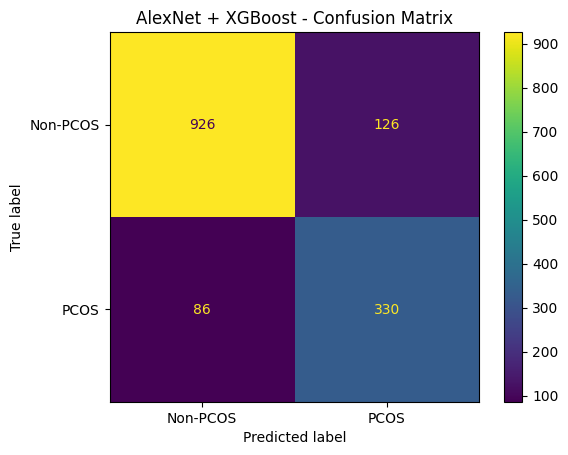

In [56]:
# ============================================================
# 4B — AlexNet + XGBoost
# ============================================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# XGBoost
alexnet_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric="logloss"
)

# Train
alexnet_xgb.fit(
    alexnet_train_features,
    alexnet_train_labels
)

# Validation
alexnet_xgb_val_pred = alexnet_xgb.predict(
    alexnet_val_features
)

alexnet_xgb_val_accuracy = accuracy_score(
    alexnet_val_labels,
    alexnet_xgb_val_pred
)

print("==============================")
print("AlexNet + XGBoost")
print("==============================")
print(f"XGBoost Validation Accuracy: {alexnet_xgb_val_accuracy:.4f}")

# Test
alexnet_xgb_test_pred = alexnet_xgb.predict(
    alexnet_test_features
)

# Metrics
alexnet_xgb_test_accuracy = accuracy_score(
    alexnet_test_labels,
    alexnet_xgb_test_pred
)

alexnet_xgb_test_precision = precision_score(
    alexnet_test_labels,
    alexnet_xgb_test_pred,
    average="weighted",
    zero_division=0
)

alexnet_xgb_test_recall = recall_score(
    alexnet_test_labels,
    alexnet_xgb_test_pred,
    average="weighted",
    zero_division=0
)

alexnet_xgb_test_f1 = f1_score(
    alexnet_test_labels,
    alexnet_xgb_test_pred,
    average="weighted",
    zero_division=0
)

print(f"XGBoost Test Accuracy: {alexnet_xgb_test_accuracy:.4f}")
print(f"XGBoost Test Precision: {alexnet_xgb_test_precision:.4f}")
print(f"XGBoost Test Recall: {alexnet_xgb_test_recall:.4f}")
print(f"XGBoost Test F1-score: {alexnet_xgb_test_f1:.4f}")

# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        alexnet_test_labels,
        alexnet_xgb_test_pred,
        labels=[0, 1],
        target_names=["Non-PCOS", "PCOS"],
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    alexnet_test_labels,
    alexnet_xgb_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-PCOS", "PCOS"]
)

disp.plot()
plt.title("AlexNet + XGBoost - Confusion Matrix")
plt.show()

# SVM

AlexNet + SVM
SVM Validation Accuracy: 0.5896
SVM Test Accuracy: 0.8474
SVM Test Precision: 0.8711
SVM Test Recall: 0.8474
SVM Test F1-score: 0.8526

Classification Report:

              precision    recall  f1-score   support

    Non-PCOS       0.95      0.83      0.89      1052
        PCOS       0.68      0.88      0.77       416

    accuracy                           0.85      1468
   macro avg       0.81      0.86      0.83      1468
weighted avg       0.87      0.85      0.85      1468



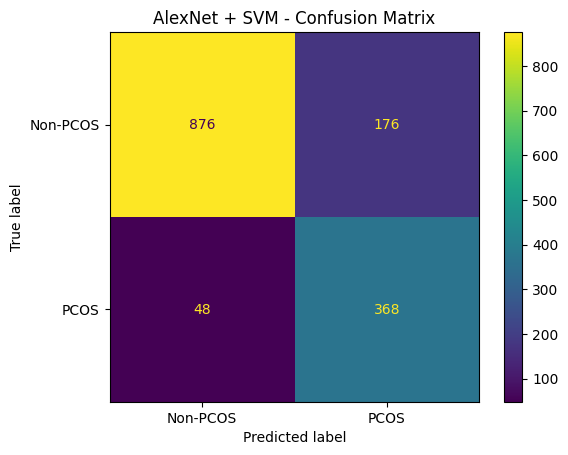

In [57]:
# ============================================================
# 4C — AlexNet + SVM
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# SVM
alexnet_svm = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)

# Train
alexnet_svm.fit(
    alexnet_train_features,
    alexnet_train_labels
)

# Validation
alexnet_svm_val_pred = alexnet_svm.predict(
    alexnet_val_features
)

alexnet_svm_val_accuracy = accuracy_score(
    alexnet_val_labels,
    alexnet_svm_val_pred
)

print("==============================")
print("AlexNet + SVM")
print("==============================")
print(f"SVM Validation Accuracy: {alexnet_svm_val_accuracy:.4f}")

# Test
alexnet_svm_test_pred = alexnet_svm.predict(
    alexnet_test_features
)

# Metrics
alexnet_svm_test_accuracy = accuracy_score(
    alexnet_test_labels,
    alexnet_svm_test_pred
)

alexnet_svm_test_precision = precision_score(
    alexnet_test_labels,
    alexnet_svm_test_pred,
    average="weighted",
    zero_division=0
)

alexnet_svm_test_recall = recall_score(
    alexnet_test_labels,
    alexnet_svm_test_pred,
    average="weighted",
    zero_division=0
)

alexnet_svm_test_f1 = f1_score(
    alexnet_test_labels,
    alexnet_svm_test_pred,
    average="weighted",
    zero_division=0
)

print(f"SVM Test Accuracy: {alexnet_svm_test_accuracy:.4f}")
print(f"SVM Test Precision: {alexnet_svm_test_precision:.4f}")
print(f"SVM Test Recall: {alexnet_svm_test_recall:.4f}")
print(f"SVM Test F1-score: {alexnet_svm_test_f1:.4f}")

# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        alexnet_test_labels,
        alexnet_svm_test_pred,
        labels=[0, 1],
        target_names=["Non-PCOS", "PCOS"],
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    alexnet_test_labels,
    alexnet_svm_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-PCOS", "PCOS"]
)

disp.plot()
plt.title("AlexNet + SVM - Confusion Matrix")
plt.show()

# Vgg16

In [58]:
# ============================================================
# 5A — VGG16 BASELINE
# Improved Fine-Tuning Version
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import models


# ============================================================
# VGG16 Model
# ============================================================

vgg16 = models.vgg16(
    pretrained=True
)


# ============================================================
# Number of Classes
# ============================================================

num_classes = len(train_dataset.classes)


# ============================================================
# Freeze VGG Initially
# ============================================================

for param in vgg16.parameters():
    param.requires_grad = False


# ============================================================
# Unfreeze LAST convolutional block
#
# VGG16 features:
# block1 -> layers 0-4
# block2 -> layers 5-9
# block3 -> layers 10-16
# block4 -> layers 17-23
# block5 -> layers 24-30
# ============================================================

for param in vgg16.features[24:].parameters():
    param.requires_grad = True


# ============================================================
# Replace Final Classifier
# ============================================================

vgg16.classifier[6] = nn.Linear(
    vgg16.classifier[6].in_features,
    num_classes
)


# Make classifier trainable
for param in vgg16.classifier.parameters():
    param.requires_grad = True


# ============================================================
# Move Model to Device
# ============================================================

vgg16 = vgg16.to(device)


# ============================================================
# Dice Loss
# ============================================================

class DiceLossVGG(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):

        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth


    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            +
            targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2.0 * intersection
            + self.smooth
        ) / (
            union
            + self.smooth
        )

        return 1.0 - dice_score.mean()


# ============================================================
# Combined CE + Dice Loss
# ============================================================

class CombinedLossVGG(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce = nn.CrossEntropyLoss()

        self.dice = DiceLossVGG(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight


    def forward(
        self,
        outputs,
        targets
    ):

        ce_loss = self.ce(
            outputs,
            targets
        )

        dice_loss = self.dice(
            outputs,
            targets
        )

        total_loss = (
            self.ce_weight * ce_loss
            +
            self.dice_weight * dice_loss
        )

        return (
            total_loss,
            ce_loss,
            dice_loss
        )


criterion_vgg = CombinedLossVGG(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# Optimizer
#
# Lower LR for pretrained convolutional layers
# Higher LR for newly initialized classifier
# ============================================================

optimizer_vgg = optim.Adam(
    [
        {
            "params": vgg16.features[24:].parameters(),
            "lr": 0.0001
        },
        {
            "params": vgg16.classifier.parameters(),
            "lr": 0.001
        }
    ]
)


# ============================================================
# Validation Function
# ============================================================

def evaluate_vgg(
    model,
    loader
):

    model.eval()

    total = 0
    correct = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(
                images
            )

            loss, ce, dice = criterion_vgg(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n_batches = len(loader)

    avg_loss = (
        running_loss /
        n_batches
    )

    avg_ce = (
        running_ce /
        n_batches
    )

    avg_dice = (
        running_dice /
        n_batches
    )

    return (
        accuracy,
        avg_loss,
        avg_ce,
        avg_dice
    )


# ============================================================
# Early Stopping
# ============================================================

best_vgg_accuracy = 0.0

best_vgg_path = (
    "/kaggle/working/VGG16_best.pkl"
)

patience = 8

epochs_no_improve = 0

max_epochs = 50


# ============================================================
# Training History
# ============================================================

vgg_train_losses = []
vgg_val_losses = []

vgg_train_accuracies = []
vgg_val_accuracies = []

vgg_train_ce_losses = []
vgg_train_dice_losses = []

vgg_val_ce_losses = []
vgg_val_dice_losses = []


# ============================================================
# Training
# ============================================================

for epoch in range(max_epochs):

    vgg16.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0


    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_vgg.zero_grad()

        outputs = vgg16(
            images
        )

        loss, ce, dice = criterion_vgg(
            outputs,
            labels
        )

        loss.backward()

        optimizer_vgg.step()


        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()


        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()


    # --------------------------------------------------------
    # Training Metrics
    # --------------------------------------------------------

    train_accuracy = (
        correct_train /
        total_train
    )

    n_batches = len(train_loader)

    train_loss = (
        running_loss /
        n_batches
    )

    train_ce = (
        running_ce /
        n_batches
    )

    train_dice = (
        running_dice /
        n_batches
    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    (
        val_accuracy,
        val_loss,
        val_ce,
        val_dice
    ) = evaluate_vgg(
        vgg16,
        val_loader
    )


    # --------------------------------------------------------
    # Save History
    # --------------------------------------------------------

    vgg_train_losses.append(
        train_loss
    )

    vgg_val_losses.append(
        val_loss
    )

    vgg_train_accuracies.append(
        train_accuracy
    )

    vgg_val_accuracies.append(
        val_accuracy
    )

    vgg_train_ce_losses.append(
        train_ce
    )

    vgg_train_dice_losses.append(
        train_dice
    )

    vgg_val_ce_losses.append(
        val_ce
    )

    vgg_val_dice_losses.append(
        val_dice
    )


    # --------------------------------------------------------
    # Early Stopping
    # --------------------------------------------------------

    if val_accuracy > best_vgg_accuracy:

        best_vgg_accuracy = val_accuracy

        epochs_no_improve = 0

        torch.save(
            vgg16.state_dict(),
            best_vgg_path
        )

    else:

        epochs_no_improve += 1

        if epochs_no_improve >= patience:

            break


# ============================================================
# Load BEST VGG16
# ============================================================

best_vgg_model = models.vgg16(
    pretrained=False
)


best_vgg_model.classifier[6] = nn.Linear(
    best_vgg_model.classifier[6].in_features,
    num_classes
)


best_vgg_model = best_vgg_model.to(device)


best_vgg_model.load_state_dict(
    torch.load(
        best_vgg_path,
        map_location=device
    )
)


best_vgg_model.eval()


# ============================================================
# VGG16 FEATURE EXTRACTION
#
# Use convolutional features only.
# Adaptive pooling gives a compact 512-dimensional vector.
# ============================================================

def extract_vgg_features(
    model,
    loader
):

    model.eval()

    features = []
    labels_list = []


    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            x = model.features(
                images
            )

            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            x = torch.flatten(
                x,
                1
            )

            features.append(
                x.cpu()
            )

            labels_list.append(
                labels.cpu()
            )


    features = torch.cat(
        features,
        dim=0
    ).numpy()

    labels_list = torch.cat(
        labels_list,
        dim=0
    ).numpy()


    return (
        features,
        labels_list
    )


# ============================================================
# TRAIN FEATURES
# ============================================================

vgg_train_features, vgg_train_labels = (
    extract_vgg_features(
        best_vgg_model,
        train_loader
    )
)


# ============================================================
# VALIDATION FEATURES
# ============================================================

vgg_val_features, vgg_val_labels = (
    extract_vgg_features(
        best_vgg_model,
        val_loader
    )
)


# ============================================================
# TEST FEATURES
# ============================================================

vgg_test_features, vgg_test_labels = (
    extract_vgg_features(
        best_vgg_model,
        test_loader
    )
)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


# XGboost

VGG16 + XGBoost
XGBoost Validation Accuracy: 0.6521
XGBoost Test Accuracy: 0.8692
XGBoost Test Precision: 0.8664
XGBoost Test Recall: 0.8692
XGBoost Test F1-score: 0.8667

Classification Report:

              precision    recall  f1-score   support

    Non-PCOS       0.89      0.93      0.91      1052
        PCOS       0.80      0.71      0.76       416

    accuracy                           0.87      1468
   macro avg       0.85      0.82      0.83      1468
weighted avg       0.87      0.87      0.87      1468



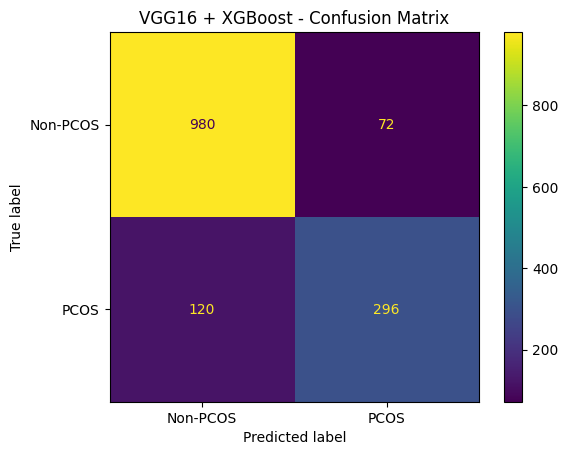

In [59]:
# ============================================================
# 5B — VGG16 + XGBoost
# ============================================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# XGBoost
vgg_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric="logloss"
)

# Train
vgg_xgb.fit(
    vgg_train_features,
    vgg_train_labels
)

# Validation
vgg_xgb_val_pred = vgg_xgb.predict(
    vgg_val_features
)

vgg_xgb_val_accuracy = accuracy_score(
    vgg_val_labels,
    vgg_xgb_val_pred
)

print("==============================")
print("VGG16 + XGBoost")
print("==============================")
print(f"XGBoost Validation Accuracy: {vgg_xgb_val_accuracy:.4f}")

# Test
vgg_xgb_test_pred = vgg_xgb.predict(
    vgg_test_features
)

# Metrics
vgg_xgb_test_accuracy = accuracy_score(
    vgg_test_labels,
    vgg_xgb_test_pred
)

vgg_xgb_test_precision = precision_score(
    vgg_test_labels,
    vgg_xgb_test_pred,
    average="weighted",
    zero_division=0
)

vgg_xgb_test_recall = recall_score(
    vgg_test_labels,
    vgg_xgb_test_pred,
    average="weighted",
    zero_division=0
)

vgg_xgb_test_f1 = f1_score(
    vgg_test_labels,
    vgg_xgb_test_pred,
    average="weighted",
    zero_division=0
)

print(f"XGBoost Test Accuracy: {vgg_xgb_test_accuracy:.4f}")
print(f"XGBoost Test Precision: {vgg_xgb_test_precision:.4f}")
print(f"XGBoost Test Recall: {vgg_xgb_test_recall:.4f}")
print(f"XGBoost Test F1-score: {vgg_xgb_test_f1:.4f}")

# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        vgg_test_labels,
        vgg_xgb_test_pred,
        labels=[0, 1],
        target_names=["Non-PCOS", "PCOS"],
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    vgg_test_labels,
    vgg_xgb_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-PCOS", "PCOS"]
)

disp.plot()
plt.title("VGG16 + XGBoost - Confusion Matrix")
plt.show()

# SVM

VGG16 + SVM
SVM Validation Accuracy: 0.5938
SVM Test Accuracy: 0.9005
SVM Test Precision: 0.9055
SVM Test Recall: 0.9005
SVM Test F1-score: 0.9020

Classification Report:

              precision    recall  f1-score   support

    Non-PCOS       0.95      0.91      0.93      1052
        PCOS       0.79      0.88      0.83       416

    accuracy                           0.90      1468
   macro avg       0.87      0.89      0.88      1468
weighted avg       0.91      0.90      0.90      1468



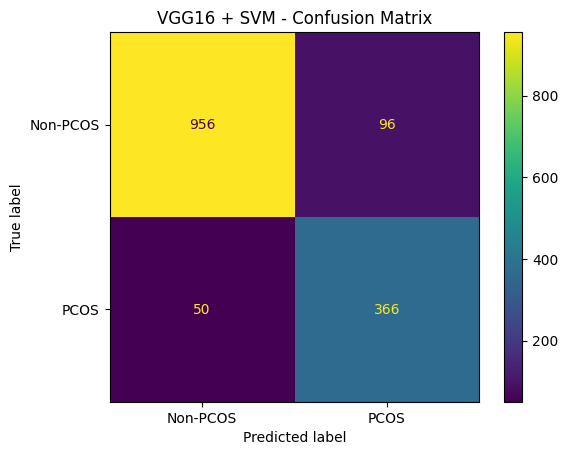

In [60]:
# ============================================================
# 5C — VGG16 + SVM
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# SVM
vgg_svm = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)

# Train
vgg_svm.fit(
    vgg_train_features,
    vgg_train_labels
)

# Validation
vgg_svm_val_pred = vgg_svm.predict(
    vgg_val_features
)

vgg_svm_val_accuracy = accuracy_score(
    vgg_val_labels,
    vgg_svm_val_pred
)

print("==============================")
print("VGG16 + SVM")
print("==============================")
print(f"SVM Validation Accuracy: {vgg_svm_val_accuracy:.4f}")

# Test
vgg_svm_test_pred = vgg_svm.predict(
    vgg_test_features
)

# Metrics
vgg_svm_test_accuracy = accuracy_score(
    vgg_test_labels,
    vgg_svm_test_pred
)

vgg_svm_test_precision = precision_score(
    vgg_test_labels,
    vgg_svm_test_pred,
    average="weighted",
    zero_division=0
)

vgg_svm_test_recall = recall_score(
    vgg_test_labels,
    vgg_svm_test_pred,
    average="weighted",
    zero_division=0
)

vgg_svm_test_f1 = f1_score(
    vgg_test_labels,
    vgg_svm_test_pred,
    average="weighted",
    zero_division=0
)

print(f"SVM Test Accuracy: {vgg_svm_test_accuracy:.4f}")
print(f"SVM Test Precision: {vgg_svm_test_precision:.4f}")
print(f"SVM Test Recall: {vgg_svm_test_recall:.4f}")
print(f"SVM Test F1-score: {vgg_svm_test_f1:.4f}")

# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        vgg_test_labels,
        vgg_svm_test_pred,
        labels=[0, 1],
        target_names=["Non-PCOS", "PCOS"],
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    vgg_test_labels,
    vgg_svm_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-PCOS", "PCOS"]
)

disp.plot()
plt.title("VGG16 + SVM - Confusion Matrix")
plt.show()